In [1]:
#配置
import os, copy, time, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("设备:", DEVICE)

NUM_CLASSES = 5
IMG_SIZE = 224
SEED = 42
N_FOLDS = 5
ABLATION_FOLD = 0

BASE = "/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2"
TRAIN_DIR = os.path.join(BASE, "train")
TEST_DIR = os.path.join(BASE, "test")
WORK_DIR = "/kaggle/working"
os.makedirs(f"{WORK_DIR}/figures", exist_ok=True)
os.makedirs(f"{WORK_DIR}/results", exist_ok=True)
os.makedirs(f"{WORK_DIR}/history", exist_ok=True)

CFG_V1 = dict(
    tag="v1", backbone="resnet18",
    use_crop=True, use_flip=True, use_rotation=True,
    use_colorjitter=True, use_erasing=True,
    use_dropout=True, dropout=0.5,
    use_ls=True, label_smoothing=0.1, wd=1e-4,
    use_freeze=True, epochs_head=8,
    lr_head=1e-3, lr_finetune=1e-4,
    epochs_finetune=30, patience=5,
    use_cosine=True,
    use_mixup=False, mixup_prob=0.5, mixup_alpha=0.2,
    batch_size=16, num_workers=0,
)
CFG_V2 = {**CFG_V1, "tag":"v2", "backbone":"efficientnet_b0",
          "epochs_finetune":40, "patience":10}

BASELINE = CFG_V1

设备: cuda


In [2]:
# ============ Cell 1: 数据 ============
def load_train_data(data_dir):
    filenames, labels = [], []
    classes = sorted(os.listdir(data_dir))
    for label, cls in enumerate(classes):
        for fname in os.listdir(os.path.join(data_dir, cls)):
            filenames.append(os.path.join(data_dir, cls, fname))
            labels.append(label)
    return filenames, labels, classes

train_files, train_labels, class_names = load_train_data(TRAIN_DIR)
print(f"样本数: {len(train_files)}, 类别: {class_names}")

class PlantDataset(Dataset):
    def __init__(self, filenames, labels, transform=None):
        self.filenames, self.labels, self.transform = filenames, labels, transform
    def __len__(self): return len(self.filenames)
    def __getitem__(self, idx):
        img = Image.open(self.filenames[idx]).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, self.labels[idx]

def build_train_transform(cfg):
    ops = [transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7,1.0))
           if cfg["use_crop"] else transforms.Resize((IMG_SIZE, IMG_SIZE))]
    if cfg["use_flip"]:        ops.append(transforms.RandomHorizontalFlip(0.5))
    if cfg["use_rotation"]:    ops.append(transforms.RandomRotation(15))
    if cfg["use_colorjitter"]: ops.append(transforms.ColorJitter(0.3,0.3,0.3,0.05))
    ops += [transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]
    if cfg["use_erasing"]:     ops.append(transforms.RandomErasing(p=0.25))
    return transforms.Compose(ops)

val_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits = list(skf.split(train_files, train_labels))

# ---------- 关键优化：缓存每个fold的val_loader（复用于混淆矩阵）----------
FOLD_DATA = {}
for fold, (tri, vai) in enumerate(splits):
    FOLD_DATA[fold] = {
        "tr_f": [train_files[i] for i in tri],
        "tr_l": [train_labels[i] for i in tri],
        "va_f": [train_files[i] for i in vai],
        "va_l": [train_labels[i] for i in vai],
    }

样本数: 500, 类别: ['Black-grass', 'Common wheat', 'Loose Silky-bent', 'Scentless Mayweed', 'Sugar beet']


In [3]:
# ============ Cell 2: 模型 ============
def build_model(cfg, pretrained=True):
    if cfg["backbone"] == "resnet18":
        w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.resnet18(weights=w)
        in_f = m.fc.in_features
        m.fc = nn.Sequential(
            nn.Dropout(cfg["dropout"]) if cfg["use_dropout"] else nn.Identity(),
            nn.Linear(in_f, NUM_CLASSES))
        head = m.fc
    elif cfg["backbone"] == "efficientnet_b0":
        w = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.efficientnet_b0(weights=w)
        in_f = m.classifier[1].in_features
        m.classifier = nn.Sequential(
            nn.Dropout(cfg["dropout"]) if cfg["use_dropout"] else nn.Identity(),
            nn.Linear(in_f, NUM_CLASSES))
        head = m.classifier
    return m.to(DEVICE), head

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [4]:
#训练核心
def set_seed(s=SEED):
    torch.manual_seed(s); np.random.seed(s)

def mixup_data(x, y, alpha):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0)).to(x.device)
    return lam*x + (1-lam)*x[idx], y, y[idx], lam

@torch.no_grad()
def evaluate(model, loader, tta=False):
    model.eval()
    preds, gts, probs = [], [], []
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE)
        out = model(imgs)
        if tta:
            out = (out + model(torch.flip(imgs, dims=[3]))) / 2
        probs.append(F.softmax(out,1).cpu().numpy())
        preds.extend(out.argmax(1).cpu().numpy())
        gts.extend(labels.numpy())
    return (f1_score(gts, preds, average='macro'),
            np.array(preds), np.array(gts), np.concatenate(probs))

def train_one_fold(cfg, tr_f, tr_l, va_f, va_l, fold=ABLATION_FOLD,
                   save_path=None, verbose=False):
    """总是返回 (best_f1, history, model, val_loader)"""
    set_seed(SEED)
    train_loader = DataLoader(PlantDataset(tr_f, tr_l, build_train_transform(cfg)),
                              batch_size=cfg["batch_size"], shuffle=True,
                              num_workers=cfg["num_workers"])
    val_loader   = DataLoader(PlantDataset(va_f, va_l, val_transform),
                              batch_size=cfg["batch_size"], shuffle=False,
                              num_workers=cfg["num_workers"])
    model, head = build_model(cfg, pretrained=True)
    criterion = nn.CrossEntropyLoss(
        label_smoothing=cfg["label_smoothing"] if cfg["use_ls"] else 0.0)

    # ---------- 阶段1：冻结 backbone ----------
    if cfg["use_freeze"]:
        for p in model.parameters(): p.requires_grad = False
        for p in head.parameters(): p.requires_grad = True
        opt = torch.optim.AdamW(head.parameters(), lr=cfg["lr_head"],
                                weight_decay=cfg["wd"])
        for epoch in range(cfg["epochs_head"]):
            model.train()
            pbar = tqdm(train_loader,
                        desc=f"[{cfg['tag']}] Head E{epoch+1}/{cfg['epochs_head']}",
                        leave=False)
            for imgs, labels in pbar:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                opt.zero_grad(); loss = criterion(model(imgs), labels)
                loss.backward(); opt.step()
                pbar.set_postfix(loss=f"{loss.item():.3f}")

    # ---------- 阶段2：微调 ----------
    for p in model.parameters(): p.requires_grad = True
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr_finetune"],
                            weight_decay=cfg["wd"])
    sched = (torch.optim.lr_scheduler.CosineAnnealingLR(
             opt, T_max=cfg["epochs_finetune"]) if cfg["use_cosine"] else None)

    best_f1, best_state, wait, history = 0, None, 0, []
    for epoch in range(cfg["epochs_finetune"]):
        model.train()
        pbar = tqdm(train_loader,
                    desc=f"[{cfg['tag']}] Fine E{epoch+1}/{cfg['epochs_finetune']}",
                    leave=False)
        for imgs, labels in pbar:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            opt.zero_grad()
            if cfg.get("use_mixup", False) and np.random.rand() < cfg.get("mixup_prob",0.5):
                imgs, ya, yb, lam = mixup_data(imgs, labels, cfg.get("mixup_alpha",0.2))
                out = model(imgs)
                loss = lam*criterion(out, ya) + (1-lam)*criterion(out, yb)
            else:
                loss = criterion(model(imgs), labels)
            loss.backward(); opt.step()
            pbar.set_postfix(loss=f"{loss.item():.3f}")
        if sched: sched.step()

        f1, _, _, _ = evaluate(model, val_loader)
        history.append(round(f1,4))
        print(f"  [{cfg['tag']}] E{epoch+1}: Macro-F1 = {f1:.4f}")
        if f1 > best_f1:
            best_f1 = f1
            best_state = {k:v.cpu().clone() for k,v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= cfg["patience"]:
                print(f"  [{cfg['tag']}] 早停 (patience={cfg['patience']})")
                break

    model.load_state_dict(best_state)
    if save_path:
        torch.save(best_state, save_path)
    return best_f1, history, model, val_loader

In [5]:
#5折训练
def run_main_5fold(cfg):
    scores, history_fold0, model_fold0, loader_fold0 = [], None, None, None
    for fold, (tri, vai) in enumerate(splits):
        d = FOLD_DATA[fold]
        print(f"\n===== {cfg['tag']} Fold {fold} =====")
        f1, hist, model, loader = train_one_fold(
            cfg, d["tr_f"], d["tr_l"], d["va_f"], d["va_l"], fold=fold,
            save_path=f"{WORK_DIR}/model_{cfg['tag']}_fold{fold}.pth")
        scores.append(f1)
        print(f"Fold {fold} best F1: {f1:.4f}")
        if fold == 0:
            history_fold0 = hist
            model_fold0 = copy.deepcopy(model)
            loader_fold0 = loader
    print(f"\n{cfg['tag']} 5折均值: {np.mean(scores):.4f}")
    return scores, history_fold0, model_fold0, loader_fold0



In [6]:
#主流程
scores_v1, history_v1, model_v1_f0, loader_v1_f0 = run_main_5fold(CFG_V1)
scores_v2, history_v2, model_v2_f0, loader_v2_f0 = run_main_5fold(CFG_V2)


===== v1 Fold 0 =====


  [v1] E1: Macro-F1 = 0.7194


  [v1] E2: Macro-F1 = 0.8719


  [v1] E3: Macro-F1 = 0.8655


  [v1] E4: Macro-F1 = 0.8775


  [v1] E5: Macro-F1 = 0.8709


... (197 outputs left out)

  [v2] E19: Macro-F1 = 0.8990


  [v2] E20: Macro-F1 = 0.8892


  [v2] E21: Macro-F1 = 0.8996


  [v2] E22: Macro-F1 = 0.8991
  [v2] 早停 (patience=10)
Fold 4 best F1: 0.9299

v2 5折均值: 0.9152


In [7]:
# ============ Cell 7: 集成 ============
test_files = sorted([os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR)])
print(f"测试集: {len(test_files)}")

def predict_probs(cfg, ckpt_path, files, tta=True):
    model, _ = build_model(cfg, pretrained=False)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()
    probs = []
    with torch.no_grad():
        for f in tqdm(files, desc=os.path.basename(ckpt_path)):
            img = Image.open(f).convert("RGB")
            x = val_transform(img).unsqueeze(0).to(DEVICE)
            p = F.softmax(model(x), 1)
            if tta:
                p = (p + F.softmax(model(torch.flip(x, dims=[3])), 1)) / 2
            probs.append(p.cpu().numpy())
    return np.concatenate(probs, 0)

model_specs = []
for fold in range(N_FOLDS):
    model_specs += [
        (CFG_V1, f"{WORK_DIR}/model_v1_fold{fold}.pth"),
        (CFG_V2, f"{WORK_DIR}/model_v2_fold{fold}.pth"),
    ]

ensemble_probs = np.zeros((len(test_files), NUM_CLASSES))
count = 0
for cfg, path in model_specs:
    if not os.path.exists(path): continue
    ensemble_probs += predict_probs(cfg, path, test_files)
    count += 1
ensemble_probs /= count
preds = ensemble_probs.argmax(1)

submission = pd.DataFrame({
    "ID": [os.path.basename(f) for f in test_files],
    "Category": [class_names[i] for i in preds]
})
submission.to_csv(f"{WORK_DIR}/submission.csv", index=False)
print(f"集成模型数: {count}")
print(submission['Category'].value_counts())

测试集: 378


model_v2_fold4.pth: 100%|██████████| 378/378 [00:11<00:00, 31.63it/s]

集成模型数: 10
Category
Loose Silky-bent     104
Scentless Mayweed     91
Sugar beet            82
Black-grass           64
Common wheat          37
Name: count, dtype: int64


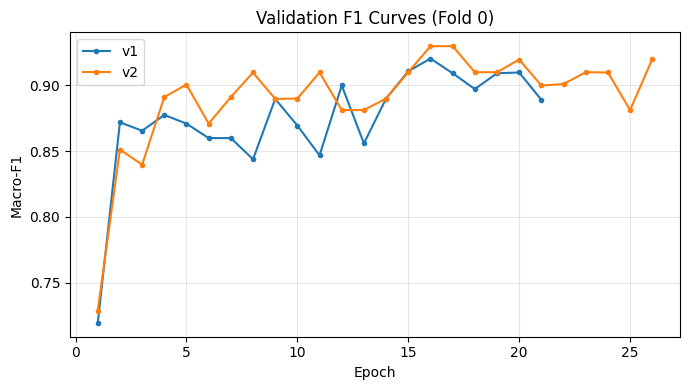

In [8]:
# ============ Cell 8: 训练曲线============
history_dict = {"v1": history_v1, "v2": history_v2}

plt.figure(figsize=(7,4))
for tag, hist in history_dict.items():
    plt.plot(range(1,len(hist)+1), hist, marker=".", label=tag)
plt.xlabel("Epoch"); plt.ylabel("Macro-F1")
plt.legend(); plt.grid(alpha=0.3)
plt.title("Validation F1 Curves (Fold 0)")
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/figures/training_curves.png", dpi=150)
plt.show()

pd.DataFrame(dict([(k,pd.Series(v)) for k,v in history_dict.items()])
             ).to_csv(f"{WORK_DIR}/results/history.csv", index=False)


===== baseline =====


  [baseline] E1: Macro-F1 = 0.7074


  [baseline] E2: Macro-F1 = 0.8719


  [baseline] E3: Macro-F1 = 0.8655


  [baseline] E4: Macro-F1 = 0.8884


  [baseline] E5: Macro-F1 = 0.8414


... (191 outputs left out)

  [efficientnet_b0] E10: Macro-F1 = 0.8900


  [efficientnet_b0] E11: Macro-F1 = 0.9098


  [efficientnet_b0] E12: Macro-F1 = 0.8812


  [efficientnet_b0] E13: Macro-F1 = 0.8812
  [efficientnet_b0] 早停 (patience=5)
→ efficientnet_b0: 0.9098

========== 消融汇总 ==========
            config  macro_f1   delta
        no_erasing    0.9207  0.0008
          baseline    0.9199  0.0000
         no_freeze    0.9107 -0.0092
        no_dropout    0.9098 -0.0101
   efficientnet_b0    0.9098 -0.0101
           no_crop    0.9009 -0.0190
         no_cosine    0.8999 -0.0200
        with_mixup    0.8999 -0.0200
no_label_smoothing    0.8999 -0.0200
           no_flip    0.8970 -0.0229
    no_colorjitter    0.8897 -0.0302
   no_weight_decay    0.8897 -0.0302
       no_rotation    0.8789 -0.0410


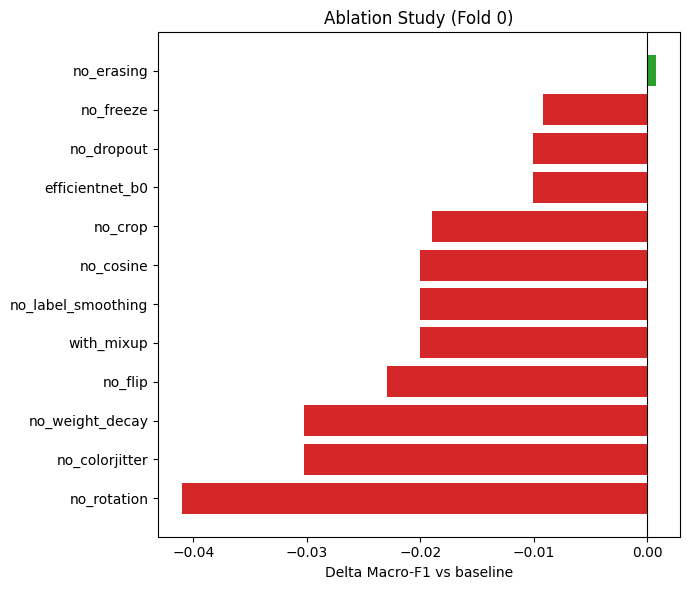

In [9]:
# ============ Cell 9: 消融============
d0 = FOLD_DATA[ABLATION_FOLD]

ablations = {
    "baseline":            {},
    "no_crop":             {"use_crop": False},
    "no_flip":             {"use_flip": False},
    "no_rotation":         {"use_rotation": False},
    "no_colorjitter":      {"use_colorjitter": False},
    "no_erasing":          {"use_erasing": False},
    "no_label_smoothing":  {"use_ls": False},
    "no_dropout":          {"use_dropout": False},
    "no_weight_decay":     {"wd": 0.0},
    "no_freeze":           {"use_freeze": False, "epochs_head": 0},
    "no_cosine":           {"use_cosine": False},
    "with_mixup":          {"use_mixup": True},
    "efficientnet_b0":     {"backbone": "efficientnet_b0"},
}

records = []
for name, override in ablations.items():
    cfg = {**BASELINE, **override, "tag": name}
    print(f"\n===== {name} =====")
    f1, _, _, _ = train_one_fold(cfg, d0["tr_f"], d0["tr_l"],
                                 d0["va_f"], d0["va_l"])
    records.append({"config": name, "macro_f1": round(f1,4)})
    print(f"→ {name}: {f1:.4f}")

df_abl = pd.DataFrame(records)
base = df_abl.loc[df_abl.config=="baseline","macro_f1"].values[0]
df_abl["delta"] = (df_abl.macro_f1 - base).round(4)
df_abl = df_abl.sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n========== 消融汇总 ==========")
print(df_abl.to_string(index=False))
df_abl.to_csv(f"{WORK_DIR}/results/ablation.csv", index=False)

# 可视化：横向条形图，按 delta 排序
df_plot = df_abl[df_abl.config != "baseline"].sort_values("delta")
plt.figure(figsize=(7,6))
colors = ["#d62728" if d < 0 else "#2ca02c" for d in df_plot["delta"]]
plt.barh(df_plot["config"], df_plot["delta"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Delta Macro-F1 vs baseline")
plt.title("Ablation Study (Fold 0)")
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/figures/ablation_bar.png", dpi=150)
plt.show()


########## lr_finetune ##########
  -- lr_finetune=1e-05 --


  [lr_finetune=1e-05] E1: Macro-F1 = 0.5474


  [lr_finetune=1e-05] E2: Macro-F1 = 0.6439


  [lr_finetune=1e-05] E3: Macro-F1 = 0.6766


  [lr_finetune=1e-05] E4: Macro-F1 = 0.7223


  [lr_finetune=1e-05] E5: Macro-F1 = 0.8011


... (173 outputs left out)

  [label_smoothing=0.2] E12: Macro-F1 = 0.8897


  [label_smoothing=0.2] E13: Macro-F1 = 0.8544


  [label_smoothing=0.2] E14: Macro-F1 = 0.8910


  [label_smoothing=0.2] E15: Macro-F1 = 0.8904
  [label_smoothing=0.2] 早停 (patience=5)
     → 0.9100


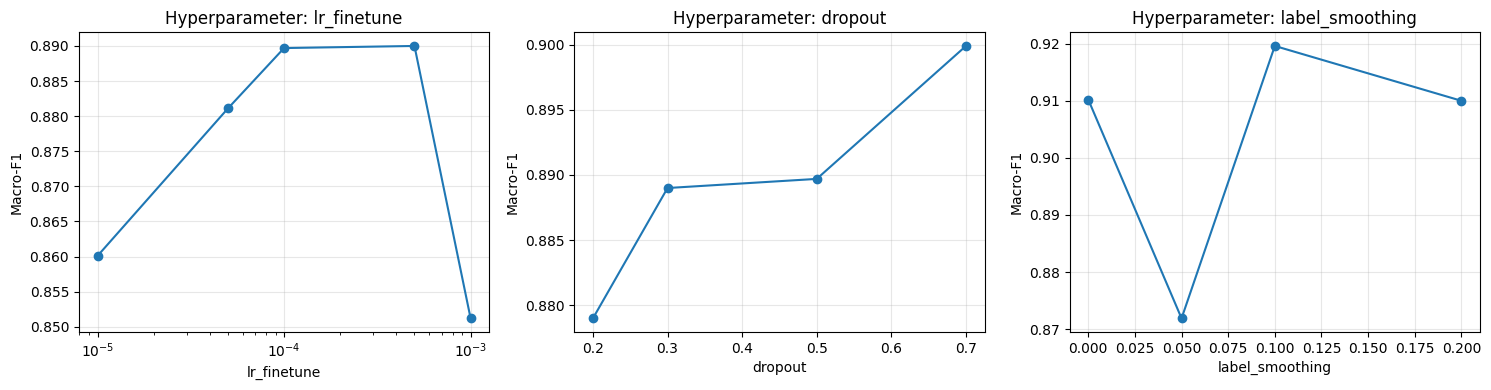


========== 超参数汇总 ==========

[lr_finetune]
  value  macro_f1
0.00001    0.8601
0.00005    0.8811
0.00010    0.8897
0.00050    0.8900
0.00100    0.8512

[dropout]
 value  macro_f1
   0.2    0.8790
   0.3    0.8890
   0.5    0.8897
   0.7    0.8999

[label_smoothing]
 value  macro_f1
  0.00    0.9102
  0.05    0.8719
  0.10    0.9196
  0.20    0.9100


In [10]:
# ============ Cell 10: 超参数 ============
d0 = FOLD_DATA[ABLATION_FOLD]

hp_grids = {
    "lr_finetune":     [1e-5, 5e-5, 1e-4, 5e-4, 1e-3],
    "dropout":         [0.2, 0.3, 0.5, 0.7],
    "label_smoothing": [0.0, 0.05, 0.1, 0.2],
}
hp_results = {}

for hp, values in hp_grids.items():
    print(f"\n########## {hp} ##########")
    rows = []
    for v in values:
        cfg = {**BASELINE, hp: v, "tag": f"{hp}={v}"}
        if hp == "label_smoothing":
            cfg["use_ls"] = v > 0
        print(f"  -- {hp}={v} --")
        f1, _, _, _ = train_one_fold(cfg, d0["tr_f"], d0["tr_l"],
                                     d0["va_f"], d0["va_l"])
        rows.append({"value": v, "macro_f1": round(f1,4)})
        print(f"     → {f1:.4f}")
    hp_results[hp] = pd.DataFrame(rows)
    hp_results[hp].to_csv(f"{WORK_DIR}/results/hp_{hp}.csv", index=False)

# 三个超参并排画图
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, (hp, df_hp) in zip(axes, hp_results.items()):
    ax.plot(df_hp["value"], df_hp["macro_f1"], marker="o")
    if hp == "lr_finetune":
        ax.set_xscale("log")
    ax.set_xlabel(hp)
    ax.set_ylabel("Macro-F1")
    ax.grid(alpha=0.3)
    ax.set_title(f"Hyperparameter: {hp}")
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/figures/hp_all.png", dpi=150)
plt.show()

# 汇总打印
print("\n========== 超参数汇总 ==========")
for hp, df_hp in hp_results.items():
    print(f"\n[{hp}]")
    print(df_hp.to_string(index=False))

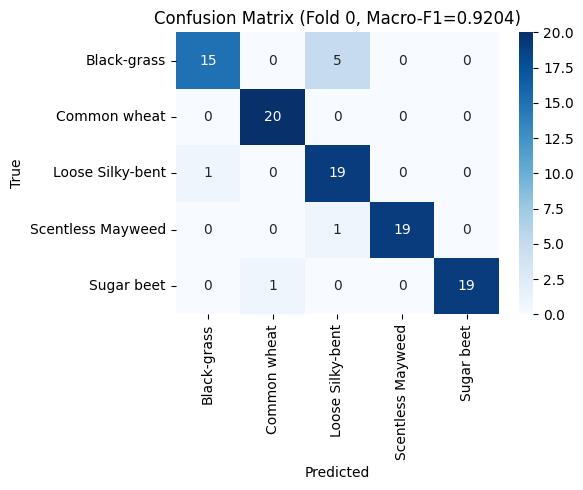


Per-class F1:
  Black-grass         : 0.8333
  Common wheat        : 0.9756
  Loose Silky-bent    : 0.8444
  Scentless Mayweed   : 0.9744
  Sugar beet          : 0.9744

错分: 8/100


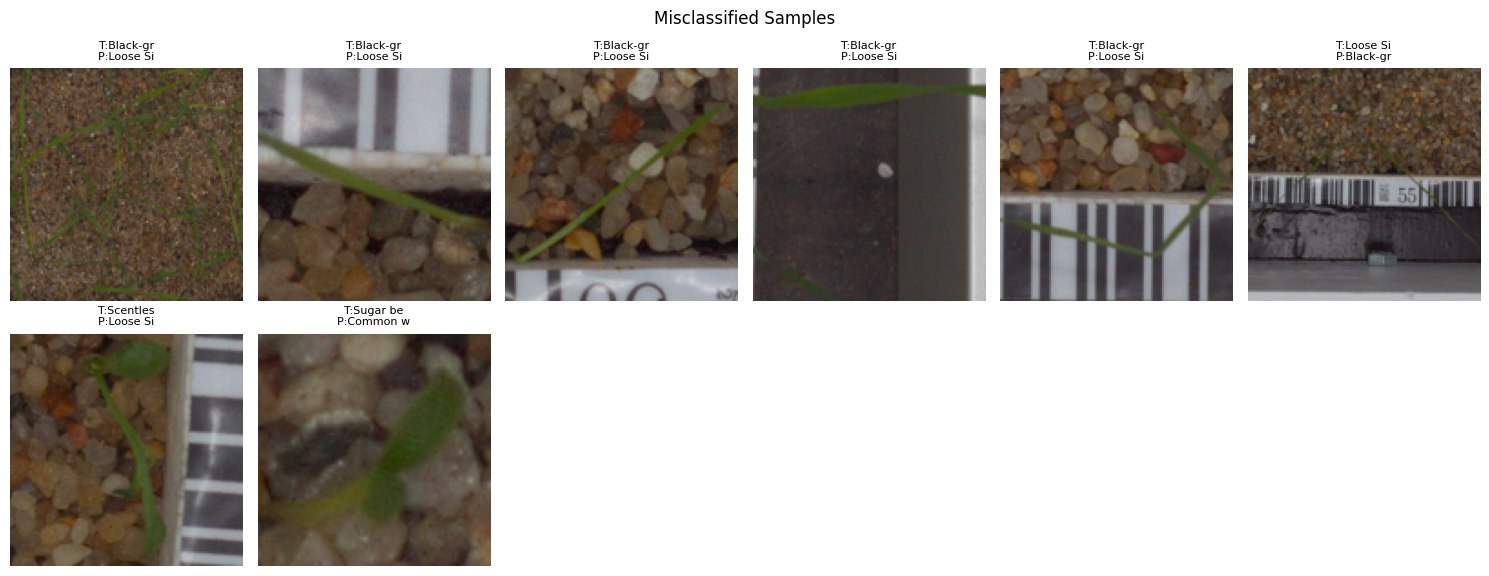

In [11]:
# ============ Cell 11: 混淆矩阵 ============
f1, preds, gts, probs = evaluate(model_v1_f0, loader_v1_f0)
cm = confusion_matrix(gts, preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix (Fold 0, Macro-F1={f1:.4f})")
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/figures/confusion_matrix.png", dpi=150)
plt.show()

per_class = f1_score(gts, preds, average=None)
print("\nPer-class F1:")
for c, f in zip(class_names, per_class):
    print(f"  {c:20s}: {f:.4f}")
pd.DataFrame({"class": class_names, "f1": per_class}
             ).to_csv(f"{WORK_DIR}/results/per_class_f1.csv", index=False)

# 错例可视化
wrong = np.where(preds != gts)[0]
print(f"\n错分: {len(wrong)}/{len(gts)}")
va_f_list = FOLD_DATA[ABLATION_FOLD]["va_f"]
plt.figure(figsize=(15,6))
for i, idx in enumerate(wrong[:12]):
    img = Image.open(va_f_list[idx]).convert("RGB").resize((128,128))
    plt.subplot(2,6,i+1); plt.imshow(img); plt.axis("off")
    plt.title(f"T:{class_names[gts[idx]][:8]}\nP:{class_names[preds[idx]][:8]}", fontsize=8)
plt.suptitle("Misclassified Samples")
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/figures/error_cases.png", dpi=150)
plt.show()

           v1      v2
count  5.0000  5.0000
mean   0.8998  0.9152
std    0.0353  0.0426
min    0.8455  0.8460
25%    0.8831  0.9103
50%    0.9203  0.9298
75%    0.9204  0.9299
max    0.9300  0.9599


/tmp/ipykernel_153/604776462.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([all_scores[k] for k in all_scores], labels=list(all_scores.keys()))


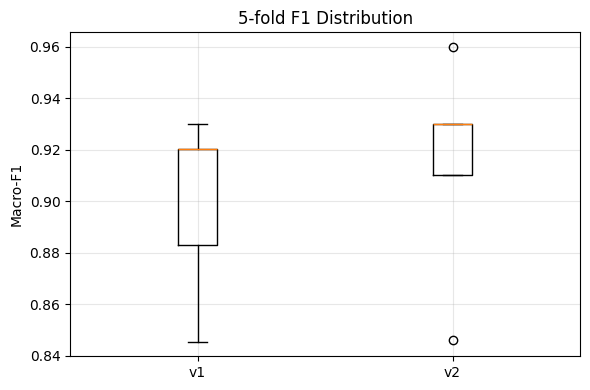


========== 模型对比 ==========
model        backbone  params(M)  mixup  5fold_mean  5fold_std   best  worst
   v1        resnet18      11.18  False      0.8998     0.0316 0.9300 0.8455
   v2 efficientnet_b0       4.01  False      0.9152     0.0381 0.9599 0.8460

========== 测试集预测分布 ==========
集成预测分布:
Category
Loose Silky-bent     104
Scentless Mayweed     91
Sugar beet            82
Black-grass           64
Common wheat          37
Name: count, dtype: int64


In [12]:
# ============ Cell 12: 稳定性 + 模型对比（复用）============
all_scores = {"v1": scores_v1, "v2": scores_v2}
df_5 = pd.DataFrame(all_scores)
print(df_5.describe().round(4))
df_5.to_csv(f"{WORK_DIR}/results/fivefold.csv", index=False)

plt.figure(figsize=(6,4))
plt.boxplot([all_scores[k] for k in all_scores], labels=list(all_scores.keys()))
plt.ylabel("Macro-F1"); plt.grid(alpha=0.3)
plt.title("5-fold F1 Distribution")
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/figures/fivefold_box.png", dpi=150)
plt.show()

# 模型对比表（参数量、均值、方差、最好/最差）
rows = []
for tag, cfg in [("v1",CFG_V1),("v2",CFG_V2)]:
    m, _ = build_model(cfg, pretrained=False)
    rows.append({
        "model": tag, "backbone": cfg["backbone"],
        "params(M)": round(count_params(m)/1e6, 2),
        "mixup": cfg["use_mixup"],
        "5fold_mean": round(np.mean(all_scores[tag]), 4),
        "5fold_std": round(np.std(all_scores[tag]), 4),
        "best": round(max(all_scores[tag]), 4),
        "worst": round(min(all_scores[tag]), 4),
    })
df_cmp = pd.DataFrame(rows)
print("\n========== 模型对比 ==========")
print(df_cmp.to_string(index=False))
df_cmp.to_csv(f"{WORK_DIR}/results/model_compare.csv", index=False)

# 额外：集成预测分布 vs 单模型预测分布
print("\n========== 测试集预测分布 ==========")
print("集成预测分布:")
print(submission['Category'].value_counts())